In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("__file__").resolve().parent
DATA = ROOT / "model_trial_responses.csv"
COLORS = {"+NO axis": "#3159a7", "+O axis": "#ef202f",
          "-NO axis": "#e68600", "-O axis": "#16843e"}

data = pd.read_csv(DATA)
data

,source,sector,observation_id,seed,condition_key,image_id,test_trial,response_NO,response_O
0,familiar,+NO axis,1,0,expert,1,1,2.117677,0.170592
1,familiar,+NO axis,1,0,expert,1,2,1.691350,-0.198027
2,familiar,+NO axis,1,0,expert,1,3,0.034057,-0.613758
3,familiar,+NO axis,1,0,expert,1,4,1.911244,0.707675
4,familiar,+NO axis,1,0,expert,1,5,1.014252,0.250047
...,...,...,...,...,...,...,...,...,...
22495,novel,-NO axis,6,9,naive,3,46,1.393188,0.549251
22496,novel,-NO axis,6,9,naive,3,47,0.336096,0.064920
22497,novel,-NO axis,6,9,naive,3,48,1.282369,0.058192
22498,novel,-NO axis,6,9,naive,3,49,2.251295,-0.240835


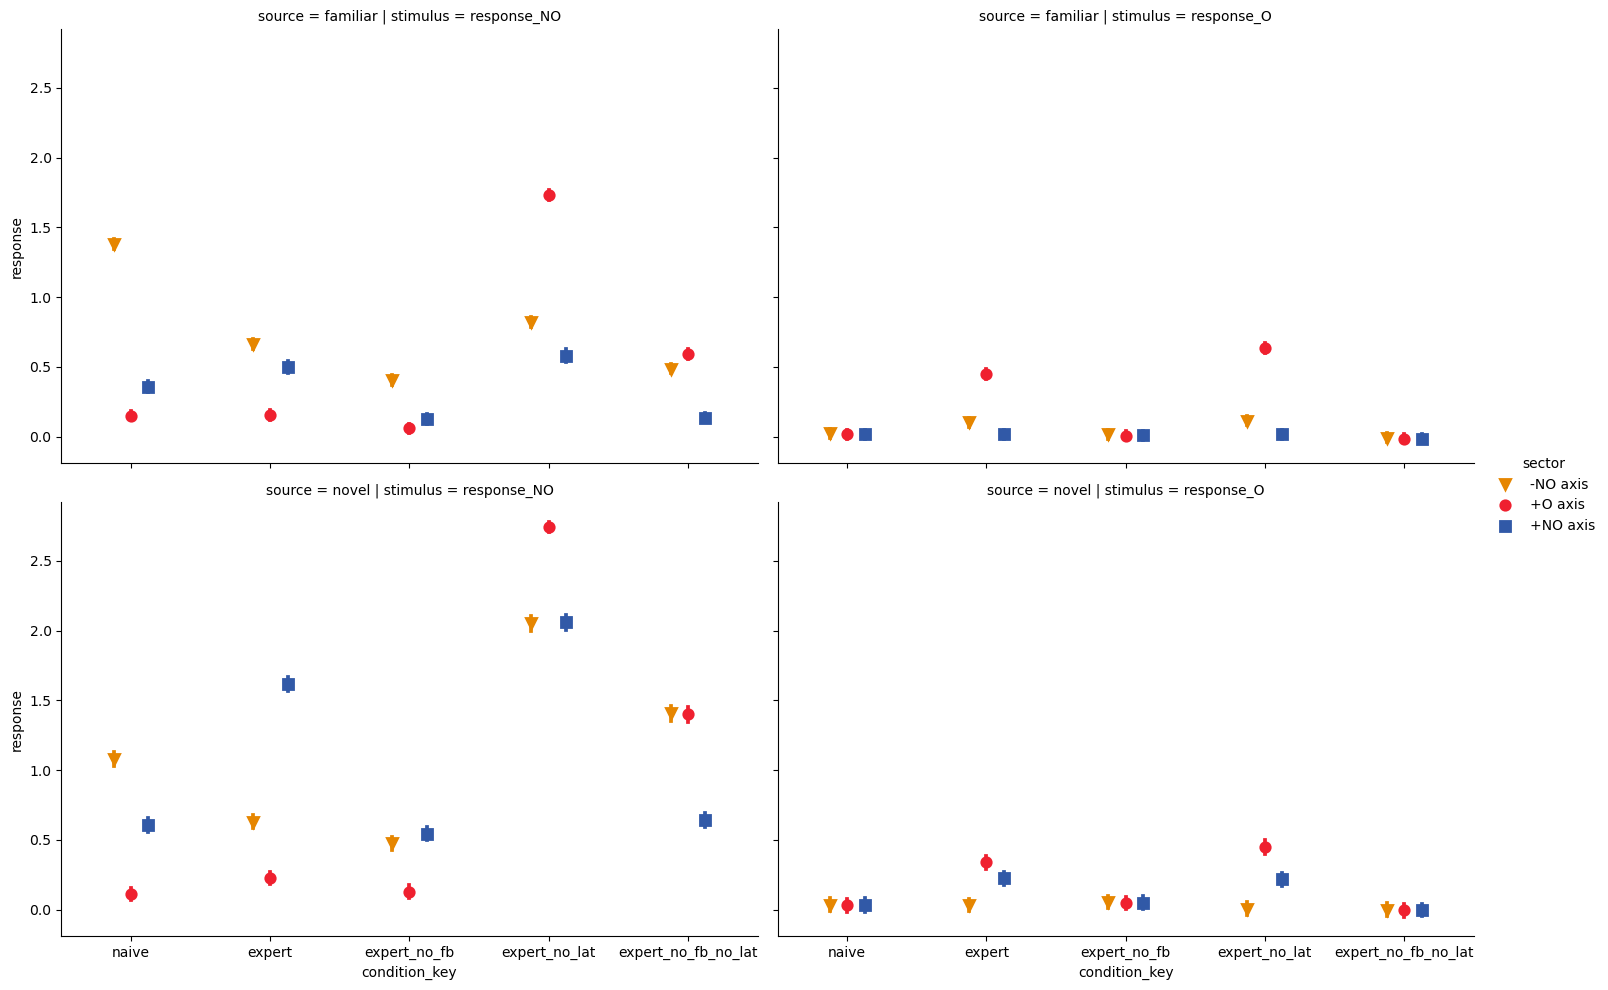

In [3]:
dat = pd.melt(data, 
        id_vars = [col for col in data.columns if "response" not in col],
        value_vars = [col for col in data.columns if "response" in col],
        var_name= 'stimulus',
        value_name='response'
        )
dat['response'] = dat.response.clip(upper=3)
sns.catplot(dat, col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', hue = 'sector', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = ['v', 'o', 's'], 
            errorbar = ('se', 2),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette=COLORS,
            aspect = 1.5)
# plt.ylim(-0.2,2)

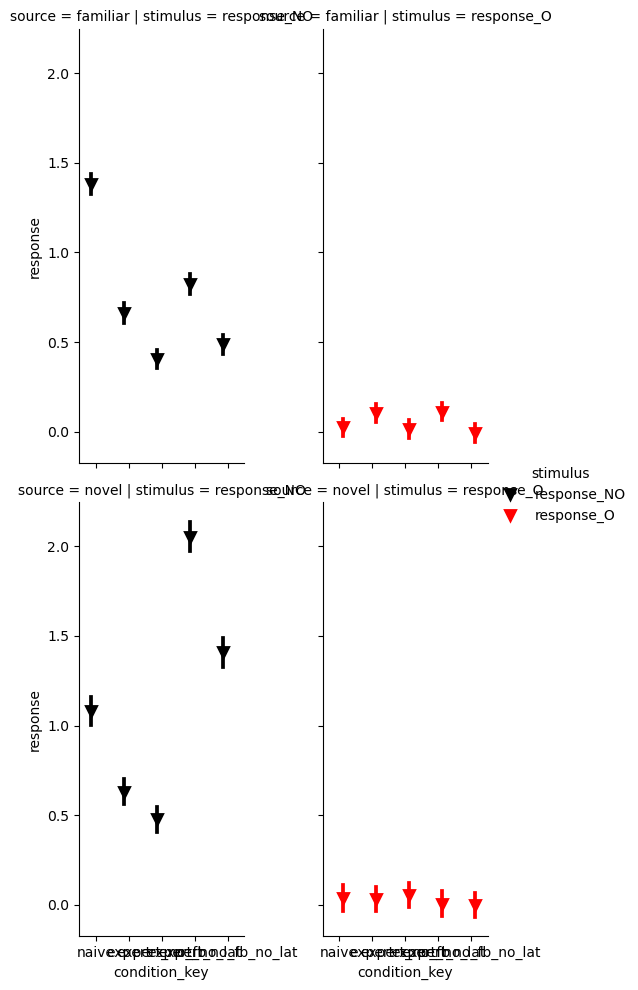

In [4]:
sns.catplot(dat.loc[dat.sector.eq('-NO axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 'v', 
            errorbar = ('se', 3),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 0.5,
            height = 5
            )

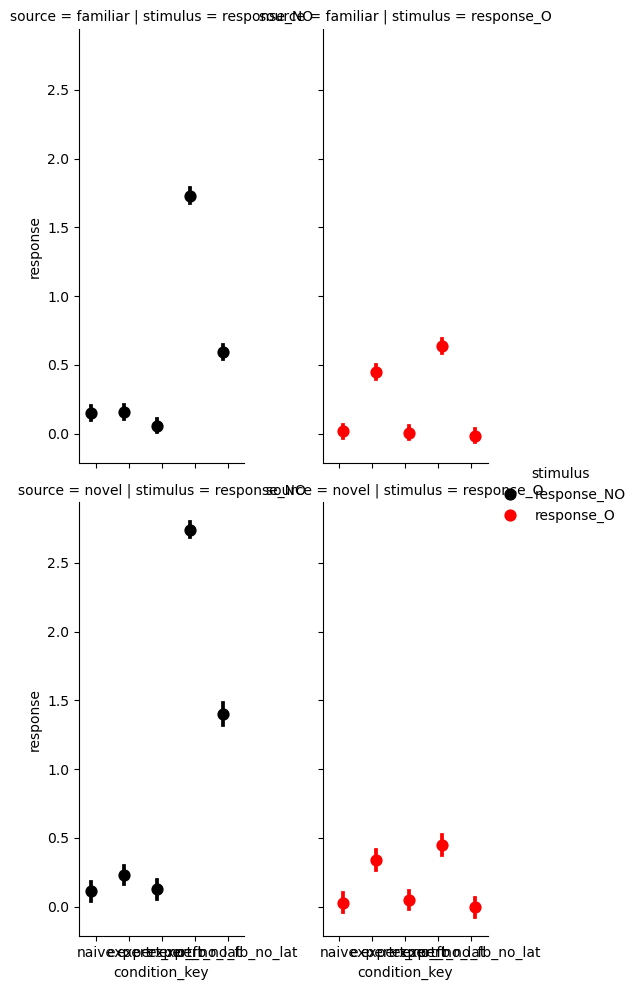

In [5]:
sns.catplot(dat.loc[dat.sector.eq('+O axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 'o', 
            errorbar = ('se', 3),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 0.5,
            height = 5
            )

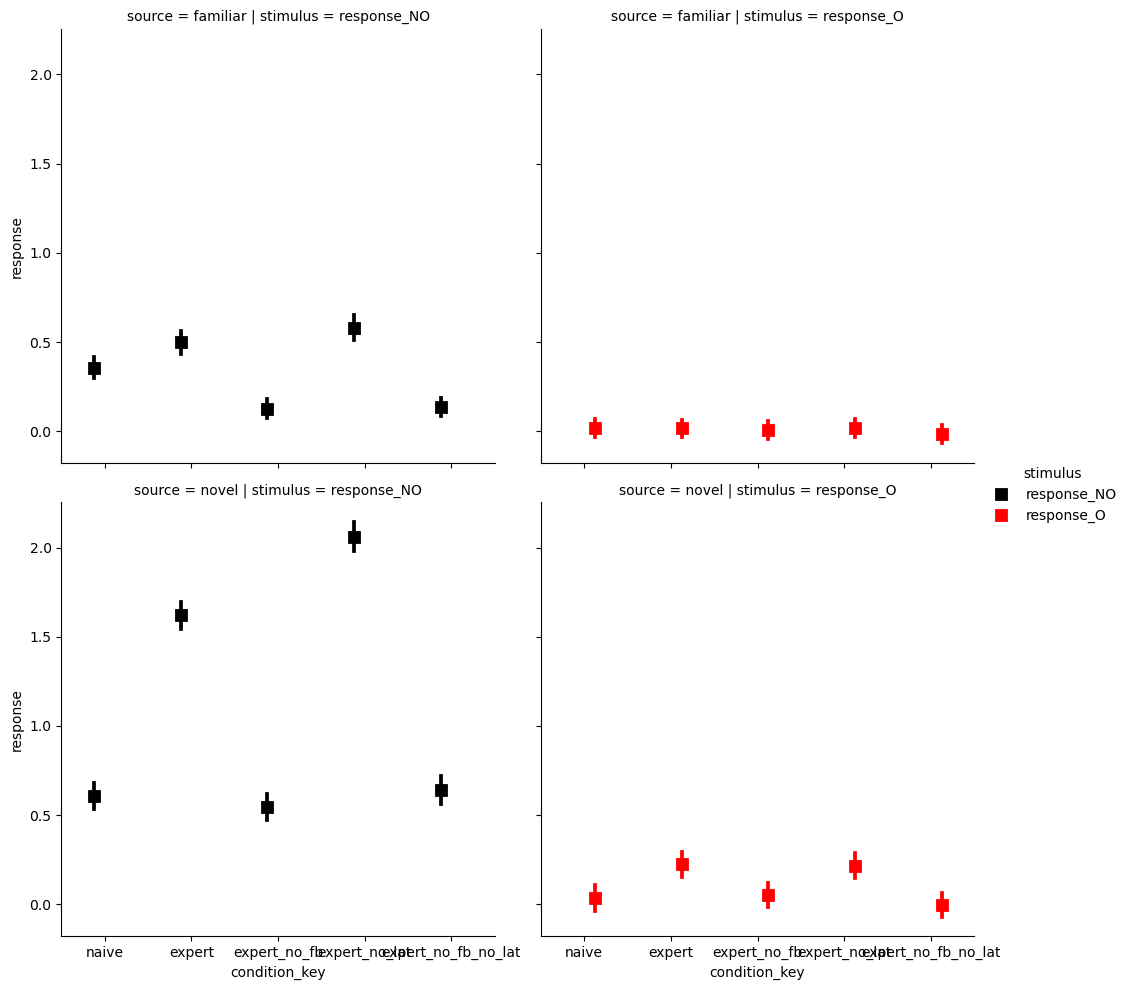

In [7]:
sns.catplot(dat.loc[dat.sector.eq('+NO axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 's', 
            errorbar = ('se', 3),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 1.0,
            height = 5
            )